# Lab 3.9 — What does one training update do?

Start with a tiny randomly initialized GPT, check a gradient by two routes, overfit one batch, then train a fresh copy on character windows. The saved base is the common starting point for the next labs.

## One batch, two ways to accumulate a gradient

Averaging equally sized microbatch losses gives the full-batch mean. Take one optimizer step only after both backward calls. AdamW tracks first and second gradient moments and applies decoupled weight decay. Watch what happens when it sees the same eight windows repeatedly.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from llm_lab.experiments import record, show

torch.manual_seed(34)
torch.set_num_threads(1)

from copy import deepcopy
from llm_lab.gpt import GPT
from llm_lab.experiments import corpus, windows, loss
text = corpus()
alphabet = sorted(set(text))
index = {ch:i for i,ch in enumerate(alphabet)}
ids = torch.tensor([index[c] for c in text])
train = ids[:7*len(ids)//10]
valid = ids[7*len(ids)//10:8*len(ids)//10]
base = GPT(len(alphabet),32,32,4,2)
demo = deepcopy(base)
batch = windows(train,torch.arange(8)*113)
large = deepcopy(base)
loss(large, batch).backward()
full = large.h[0].attn.c_attn.weight.grad.clone()
for start in (0,4):
    (loss(demo,tuple(t[start:start+4] for t in batch))/2).backward()
torch.testing.assert_close(demo.h[0].attn.c_attn.weight.grad,full,atol=1e-6,rtol=1e-4)
# Step both copies exactly once. Reset the demo for the memorization experiment.
for candidate in (large, demo):
    torch.optim.AdamW(candidate.parameters(), lr=.004).step()
full_logits = large(batch[0]).detach()
micro_logits = demo(batch[0]).detach()
print("One-step max logit difference:", (full_logits - micro_logits).abs().max().item())
torch.testing.assert_close(full_logits, micro_logits, atol=2e-4, rtol=1e-5)
demo = deepcopy(base)
opt = torch.optim.AdamW(demo.parameters(),lr=.004)
before = loss(demo,batch).item()
for _ in range(100):
    opt.zero_grad()
    loss(demo,batch).backward()
    opt.step()
print("Repeated-batch loss:", before, "→", loss(demo,batch).item())

One-step max logit difference: 5.7220458984375e-06
Repeated-batch loss: 19.064626693725586 → 0.012848371639847755


## Train a base model on new windows

Separate contiguous text before drawing windows. Evaluate fixed validation windows and track their loss as the learning rate warms up and decays. A falling repeated-batch loss established capacity to memorize. What would count as evidence of generalization?

Validation nats per character: 18.97258949279785 → 3.025296449661255
Out[2]: PosixPath('checkpoints/lab39/dense_base.npz')


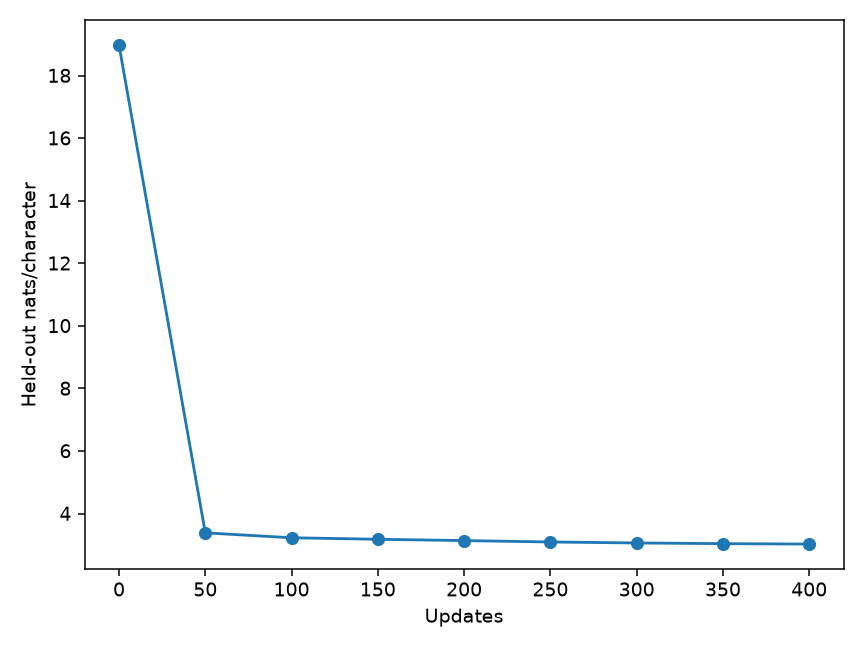

In [2]:
import math
opt = torch.optim.AdamW(base.parameters(),lr=.003)
held = windows(valid,torch.linspace(0,len(valid)-33,128).long())
scores = []
for step in range(401):
    if step % 50 == 0:
        with torch.no_grad():
            scores.append(loss(base,held).item())
    if step == 400:
        break
    lr = .003 * min((step+1)/20,1) * (.55+.45*math.cos(math.pi*step/400))
    opt.param_groups[0]["lr"] = lr
    opt.zero_grad()
    loss(base,windows(train,torch.randint(len(train)-32,(48,)))).backward()
    opt.step()
print("Validation nats per character:", scores[0], "→", scores[-1])
plt.plot(range(0,401,50),scores,marker="o"); plt.ylabel("Held-out nats/character"); plt.xlabel("Updates")
show(39,"dense_loss")
record(39,"dense_base",alphabet=alphabet,validation=scores,**{k:v.detach() for k,v in base.state_dict().items()})

## Reading the result

On the repeated batch, loss fell from 19.06 to 0.013. The separate run on fresh windows reduced validation loss from 18.97 to 3.03 nats per character. The two experiments answer different questions. The first checks whether gradients and parameters can fit known examples. The second measures prediction on a disjoint slice of text. What would you inspect if only the first result improved?